# 03 — Models, evaluation and explanation
Requires notebook 02. Stratified random subscriber split. Full-cohort EDA preceded splitting; this is not an untouched temporal validation. Aggregate outputs are also available in reports/tables/ and reports/figures/.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.json").exists() and (p / "src" / "common.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the repository folder")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.common import paths, save_frame, load_frame
config, project_paths = paths(ROOT)
data_dir = project_paths["raw"]
processed_dir = project_paths["processed"]
figures_dir = project_paths["figures"]
tables_dir = project_paths["tables"]
artifacts_dir = project_paths["artifacts"]
cutoff = pd.Timestamp(config["cutoff"])


In [2]:
from src.features import model_inputs, NUMERIC_FEATURES, CATEGORICAL_FEATURES
campaign = load_frame(processed_dir / 'modeling_table.csv.gz')
X, y = model_inputs(campaign)
numeric_features = NUMERIC_FEATURES
categorical_features = CATEGORICAL_FEATURES


In [3]:


from sklearn.model_selection import train_test_split

# Reserve 20% for final testing.
X_development, X_test, y_development, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Split the remaining 80% into 60% training and 20% validation.
X_train, X_valid, y_train, y_valid = train_test_split(
    X_development,
    y_development,
    test_size=0.25,
    stratify=y_development,
    random_state=42
)

split_summary = pd.DataFrame({
    "split": ["Training", "Validation", "Test"],
    "subscribers": [len(y_train), len(y_valid), len(y_test)],
    "churn_rate": [y_train.mean(), y_valid.mean(), y_test.mean()]
})

display(
    split_summary.style.format({
        "subscribers": "{:,.0f}",
        "churn_rate": "{:.2%}"
    })
)

assert X_train.index.intersection(X_valid.index).empty
assert X_train.index.intersection(X_test.index).empty
assert X_valid.index.intersection(X_test.index).empty

,split,subscribers,churn_rate
0,Training,"564,910",7.97%
1,Validation,"188,304",7.97%
2,Test,"188,304",7.97%


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score
import numpy as np
import pandas as pd

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        ), categorical_features)
    ],
    sparse_threshold=1.0
)

baseline_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(
        solver="lbfgs",
        max_iter=1000,
        C=1.0
    ))
])

baseline_model.fit(X_train, y_train)

# Predict probabilities on validation data.
valid_probabilities = baseline_model.predict_proba(X_valid)[:, 1]

# Reference: give everyone the training-set churn probability.
constant_probabilities = np.full(len(y_valid), y_train.mean())

results = pd.DataFrame({
    "model": ["Constant probability", "Logistic regression"],
    "log_loss": [
        log_loss(y_valid, constant_probabilities),
        log_loss(y_valid, valid_probabilities)
    ],
    "roc_auc": [
        roc_auc_score(y_valid, constant_probabilities),
        roc_auc_score(y_valid, valid_probabilities)
    ]
})

display(results.round(4))

,model,log_loss,roc_auc
0,Constant probability,0.2780,0.5000
1,Logistic regression,0.1777,0.8551


In [5]:
validation_predictions = pd.DataFrame({
    "actual_churn": y_valid.to_numpy(),
    "predicted_probability": valid_probabilities
})

# Divide subscribers into approximately equal-sized risk groups.
validation_predictions["risk_group"] = pd.qcut(
    validation_predictions["predicted_probability"],
    q=10,
    duplicates="drop"
)

calibration_summary = (
    validation_predictions.groupby("risk_group", observed=True)
    .agg(
        subscribers=("actual_churn", "size"),
        mean_predicted_risk=("predicted_probability", "mean"),
        actual_churn_rate=("actual_churn", "mean")
    )
    .reset_index()
)

display(
    calibration_summary.style.format({
        "subscribers": "{:,.0f}",
        "mean_predicted_risk": "{:.2%}",
        "actual_churn_rate": "{:.2%}"
    })
)

,risk_group,subscribers,mean_predicted_risk,actual_churn_rate
0,"(0.0007799999999999999, 0.0161]","18,831",1.23%,1.36%
1,"(0.0161, 0.0183]","18,833",1.72%,2.59%
2,"(0.0183, 0.0205]","18,831",1.94%,2.19%
3,"(0.0205, 0.0228]","18,827",2.16%,2.57%
4,"(0.0228, 0.0257]","18,863",2.42%,2.77%
5,"(0.0257, 0.0287]","18,797",2.72%,1.26%
6,"(0.0287, 0.0343]","18,839",3.11%,2.70%
7,"(0.0343, 0.0461]","18,822",3.93%,2.80%
8,"(0.0461, 0.268]","18,830",11.66%,10.08%
9,"(0.268, 1.0]","18,831",49.53%,51.34%


Highest-risk group size: 18,831
Share of churners captured: 64.43%
Lift over random targeting: 6.44x


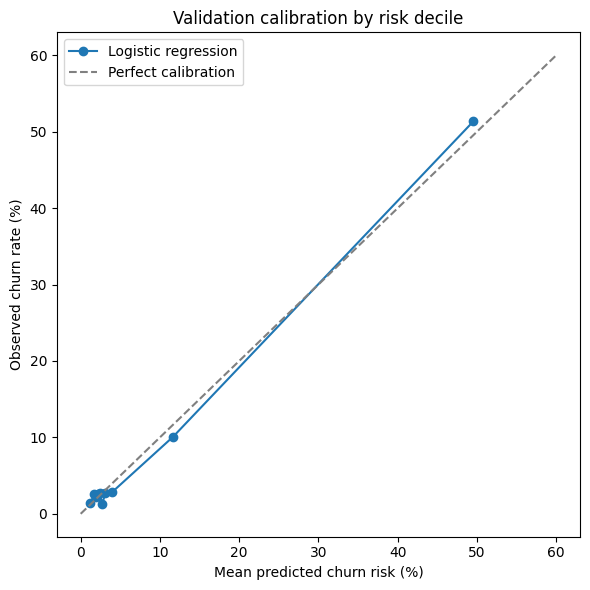

In [6]:
import matplotlib.pyplot as plt

highest_risk = validation_predictions.loc[
    validation_predictions["risk_group"]
    == calibration_summary.iloc[-1]["risk_group"]
]

capture_rate = (
    highest_risk["actual_churn"].sum()
    / validation_predictions["actual_churn"].sum()
)

lift = (
    highest_risk["actual_churn"].mean()
    / validation_predictions["actual_churn"].mean()
)

print(f"Highest-risk group size: {len(highest_risk):,}")
print(f"Share of churners captured: {capture_rate:.2%}")
print(f"Lift over random targeting: {lift:.2f}x")

fig, ax = plt.subplots(figsize=(6, 6))

ax.plot(
    calibration_summary["mean_predicted_risk"] * 100,
    calibration_summary["actual_churn_rate"] * 100,
    marker="o",
    label="Logistic regression"
)
ax.plot([0, 60], [0, 60], "--", color="gray", label="Perfect calibration")

ax.set(
    xlabel="Mean predicted churn risk (%)",
    ylabel="Observed churn rate (%)",
    title="Validation calibration by risk decile"
)
ax.legend()
fig.tight_layout()
plt.show()

In [7]:
import lightgbm as lgb

# Prepare separate copies for LightGBM.
X_train_lgb = X_train.copy()
X_valid_lgb = X_valid.copy()

# Learn category definitions from training data only.
category_types = {}

for column in categorical_features:
    category_types[column] = pd.CategoricalDtype(
        categories=X_train[column].unique()
    )

    X_train_lgb[column] = X_train[column].astype(category_types[column])
    X_valid_lgb[column] = X_valid[column].astype(category_types[column])

# Numeric missing values remain missing.
lgb_model = lgb.LGBMClassifier(
    objective="binary",
    n_estimators=2000,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=100,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=4,
    verbosity=-1
)

lgb_model.fit(
    X_train_lgb,
    y_train,
    categorical_feature=categorical_features,
    eval_set=[(X_valid_lgb, y_valid)],
    eval_metric="binary_logloss",
    callbacks=[
        lgb.early_stopping(stopping_rounds=50),
        lgb.log_evaluation(period=100)
    ]
)

lgb_valid_probabilities = lgb_model.predict_proba(X_valid_lgb)[:, 1]

comparison = pd.DataFrame({
    "model": ["Logistic regression", "LightGBM"],
    "log_loss": [
        log_loss(y_valid, valid_probabilities),
        log_loss(y_valid, lgb_valid_probabilities)
    ],
    "roc_auc": [
        roc_auc_score(y_valid, valid_probabilities),
        roc_auc_score(y_valid, lgb_valid_probabilities)
    ]
})

print("Best LightGBM iteration:", lgb_model.best_iteration_)
display(comparison.round(4))

Training until validation scores don't improve for 50 rounds
[100]	valid_0's binary_logloss: 0.157874
[200]	valid_0's binary_logloss: 0.155482
[300]	valid_0's binary_logloss: 0.155057
[400]	valid_0's binary_logloss: 0.154893
[500]	valid_0's binary_logloss: 0.154815
[600]	valid_0's binary_logloss: 0.154734
[700]	valid_0's binary_logloss: 0.154681
[800]	valid_0's binary_logloss: 0.154653
[900]	valid_0's binary_logloss: 0.154642
[1000]	valid_0's binary_logloss: 0.154614
[1100]	valid_0's binary_logloss: 0.154599
Early stopping, best iteration is:
[1131]	valid_0's binary_logloss: 0.154584
Best LightGBM iteration: 1131


,model,log_loss,roc_auc
0,Logistic regression,0.1777,0.8551
1,LightGBM,0.1546,0.9066


In [8]:
lgb_validation = pd.DataFrame({
    "actual_churn": y_valid.to_numpy(),
    "predicted_probability": lgb_valid_probabilities
})

# Select the same number of subscribers as the baseline's top-risk group.
top_n = len(highest_risk)

lgb_top = lgb_validation.nlargest(
    top_n, "predicted_probability"
)

capture = (
    lgb_top["actual_churn"].sum()
    / lgb_validation["actual_churn"].sum()
)

lift = (
    lgb_top["actual_churn"].mean()
    / lgb_validation["actual_churn"].mean()
)

print("Best iteration:", lgb_model.best_iteration_)
print(f"Top-group subscribers: {top_n:,}")
print(f"Share of churners captured: {capture:.2%}")
print(f"Lift over random targeting: {lift:.2f}x")

lgb_validation["risk_group"] = pd.qcut(
    lgb_validation["predicted_probability"],
    q=10,
    duplicates="drop"
)

lgb_calibration = (
    lgb_validation.groupby("risk_group", observed=True)
    .agg(
        subscribers=("actual_churn", "size"),
        mean_predicted_risk=("predicted_probability", "mean"),
        actual_churn_rate=("actual_churn", "mean")
    )
    .reset_index()
)

display(
    lgb_calibration.style.format({
        "subscribers": "{:,.0f}",
        "mean_predicted_risk": "{:.2%}",
        "actual_churn_rate": "{:.2%}"
    })
)

Best iteration: 1131
Top-group subscribers: 18,831
Share of churners captured: 68.09%
Lift over random targeting: 6.81x


,risk_group,subscribers,mean_predicted_risk,actual_churn_rate
0,"(0.00034, 0.00586]","18,872",0.39%,0.37%
1,"(0.00586, 0.00853]","18,893",0.72%,0.57%
2,"(0.00853, 0.0107]","18,735",0.97%,1.05%
3,"(0.0107, 0.015]","18,849",1.25%,1.35%
4,"(0.015, 0.0205]","18,813",1.79%,1.84%
5,"(0.0205, 0.0259]","18,820",2.30%,2.38%
6,"(0.0259, 0.0342]","18,831",2.95%,3.09%
7,"(0.0342, 0.0541]","18,830",4.21%,3.67%
8,"(0.0541, 0.216]","18,830",11.69%,11.10%
9,"(0.216, 1.0]","18,831",53.83%,54.25%


In [9]:
# Apply category definitions learned from training data.
X_test_lgb = X_test.copy()

for column in categorical_features:
    X_test_lgb[column] = X_test[column].astype(category_types[column])

# Evaluate the already-fitted models.
logistic_test_probabilities = baseline_model.predict_proba(X_test)[:, 1]

lgb_test_probabilities = lgb_model.predict_proba(
    X_test_lgb,
    num_iteration=lgb_model.best_iteration_
)[:, 1]


def evaluate_predictions(y_true, probabilities):
    actual = np.asarray(y_true)
    probabilities = np.asarray(probabilities)

    top_n = int(np.ceil(len(actual) * 0.10))
    top_indices = np.argsort(-probabilities, kind="stable")[:top_n]

    return {
        "log_loss": log_loss(actual, probabilities),
        "roc_auc": roc_auc_score(actual, probabilities),
        "top_10pct_capture": actual[top_indices].sum() / actual.sum(),
        "top_10pct_lift": actual[top_indices].mean() / actual.mean()
    }


test_results = pd.DataFrame({
    "Logistic regression": evaluate_predictions(
        y_test, logistic_test_probabilities
    ),
    "LightGBM": evaluate_predictions(
        y_test, lgb_test_probabilities
    )
}).T

display(
    test_results.style.format({
        "log_loss": "{:.4f}",
        "roc_auc": "{:.4f}",
        "top_10pct_capture": "{:.2%}",
        "top_10pct_lift": "{:.2f}x"
    })
)

,log_loss,roc_auc,top_10pct_capture,top_10pct_lift
Logistic regression,0.1777,0.8578,64.49%,6.45x
LightGBM,0.1554,0.9068,67.54%,6.75x


,feature,mean_absolute_shap
0,latest_is_auto_renew,0.462878
1,days_since_latest_transaction,0.301594
2,latest_payment_method_id,0.274758
3,history_days_since_first_transaction,0.237006
4,latest_plan_list_price,0.235549
5,history_transaction_count,0.194828
6,tenure_days,0.115476
7,age_clean,0.111568
8,days_to_expiry,0.094929
9,city,0.051799


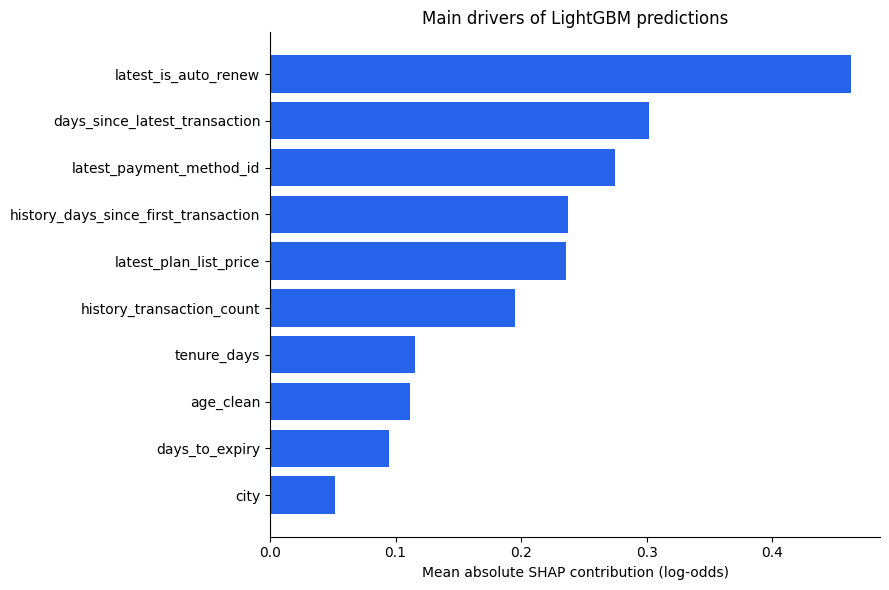

In [10]:
# Use validation data to explain the frozen model.
X_explain = X_valid_lgb.sample(n=5000, random_state=42)

contributions = lgb_model.booster_.predict(
    X_explain,
    pred_contrib=True,
    num_iteration=lgb_model.best_iteration_
)

# The last column is the baseline value, not a feature contribution.
shap_values = contributions[:, :-1]

shap_importance = (
    pd.DataFrame({
        "feature": X_explain.columns,
        "mean_absolute_shap": np.abs(shap_values).mean(axis=0)
    })
    .sort_values("mean_absolute_shap", ascending=False)
    .reset_index(drop=True)
)

display(shap_importance.head(10))

top_features = shap_importance.head(10).sort_values(
    "mean_absolute_shap"
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    top_features["feature"],
    top_features["mean_absolute_shap"],
    color="#2563EB"
)

ax.set_xlabel("Mean absolute SHAP contribution (log-odds)")
ax.set_title("Main drivers of LightGBM predictions")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

fig.savefig(
    figures_dir / "lightgbm_shap_importance.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [11]:
for feature in [
    "latest_is_auto_renew",
    "days_since_latest_transaction",
    "latest_payment_method_id"
]:
    feature_position = X_explain.columns.get_loc(feature)

    explanation = pd.DataFrame({
        "feature_value": X_explain[feature].to_numpy(),
        "shap_contribution": shap_values[:, feature_position]
    })

    if feature == "days_since_latest_transaction":
        explanation["group"] = pd.cut(
            explanation["feature_value"],
            bins=[-1, 7, 14, 30, 90, np.inf],
            labels=["0–7", "8–14", "15–30", "31–90", "Over 90"]
        )
    else:
        explanation["group"] = explanation["feature_value"]

    direction_summary = (
        explanation.groupby("group", observed=True, dropna=False)
        .agg(
            subscribers=("shap_contribution", "size"),
            mean_shap=("shap_contribution", "mean"),
            median_shap=("shap_contribution", "median")
        )
    )

    print(f"\n{feature}")
    display(direction_summary.round(4))


latest_is_auto_renew


,subscribers,mean_shap,median_shap
group,,,
0.0,585,1.8637,2.0576
1.0,4415,-0.2751,-0.2765



days_since_latest_transaction


,subscribers,mean_shap,median_shap
group,,,
0–7,1618,-0.2472,-0.2511
8–14,997,-0.1915,-0.1818
15–30,2195,-0.0190,-0.0342
31–90,77,3.6838,3.6223
Over 90,113,4.0853,3.8840



latest_payment_method_id


,subscribers,mean_shap,median_shap
group,,,
13.0,5,-0.2602,-0.2306
15.0,3,1.1111,1.0601
16.0,4,0.5283,0.5625
17.0,1,0.6818,0.6818
18.0,5,0.0556,0.0154
19.0,6,-0.4095,-0.4097
20.0,6,-0.0671,-0.0337
21.0,5,-0.5625,-0.4960
22.0,4,-0.1671,-0.1587


In [12]:
# Persist models, schemas, split membership, and predictions for notebook 04.
import joblib
from importlib.metadata import version
joblib.dump(baseline_model, artifacts_dir / 'logistic_pipeline.joblib')
joblib.dump({'model': lgb_model, 'category_types': category_types,
             'feature_order': list(X.columns)}, artifacts_dir / 'lightgbm_bundle.joblib')
lgb_model.booster_.save_model(str(artifacts_dir / 'lightgbm.txt'), num_iteration=lgb_model.best_iteration_)
metadata = {'config': config, 'best_iteration': int(lgb_model.best_iteration_),
    'numeric': numeric_features, 'categorical': categorical_features,
    'categories': {k: list(v.categories) for k, v in category_types.items()},
    'versions': {p: version(p) for p in ['pandas','numpy','scikit-learn','lightgbm','matplotlib','joblib']}}
(artifacts_dir / 'metadata.json').write_text(json.dumps(metadata, indent=2))
split_frames = []
for name, features in [('train', X_train), ('validation', X_valid), ('test', X_test)]:
    part = campaign.loc[features.index, ['msno']].copy()
    part['split'] = name
    split_frames.append(part)
save_frame(pd.concat(split_frames), artifacts_dir / 'split_membership.csv.gz')
for name, features, target, prob in [
    ('validation', X_valid, y_valid, lgb_valid_probabilities),
    ('test', X_test, y_test, lgb_test_probabilities)]:
    frame = campaign.loc[features.index, ['msno','is_churn','revenue_30d_proxy']].copy()
    assert frame.msno.is_unique and np.array_equal(frame.is_churn.to_numpy(), target.to_numpy())
    frame['predicted_churn_probability'] = prob
    save_frame(frame, artifacts_dir / f'{name}_predictions.csv.gz')
comparison.to_csv(tables_dir / 'validation_metrics.csv', index=False)
test_results.to_csv(tables_dir / 'test_metrics.csv')
shap_importance.to_csv(tables_dir / 'shap_importance.csv', index=False)
lgb_calibration.to_csv(tables_dir / 'lightgbm_validation_calibration.csv', index=False)


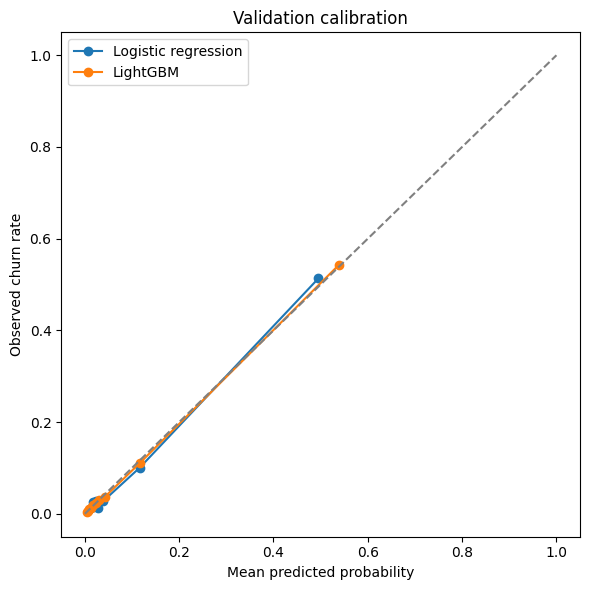

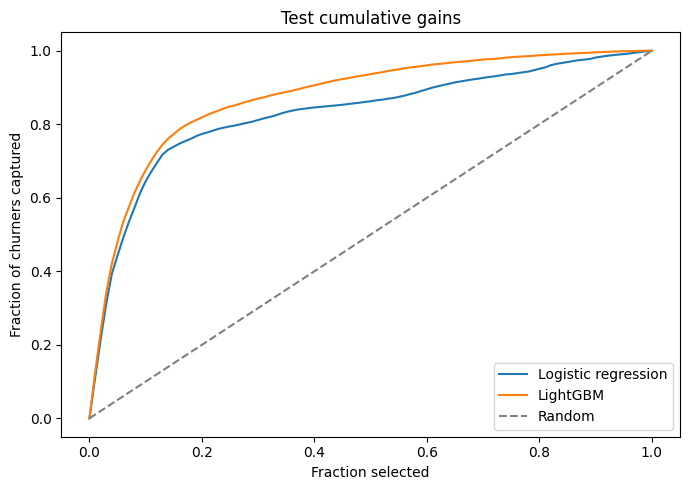

In [13]:
# Save calibration and full cumulative gains figures.
fig, ax = plt.subplots(figsize=(6, 6))
for label, frame in [('Logistic regression', calibration_summary), ('LightGBM', lgb_calibration)]:
    ax.plot(frame.mean_predicted_risk, frame.actual_churn_rate, marker='o', label=label)
ax.plot([0, 1], [0, 1], '--', color='gray')
ax.set(xlabel='Mean predicted probability', ylabel='Observed churn rate', title='Validation calibration')
ax.legend(); fig.tight_layout()
fig.savefig(figures_dir / 'validation_calibration.png', dpi=200)
plt.show()
fig, ax = plt.subplots(figsize=(7, 5))
gains_rows = []
for label, prob in [('Logistic regression', logistic_test_probabilities), ('LightGBM', lgb_test_probabilities)]:
    order = np.argsort(-prob, kind='stable')
    cumulative = np.cumsum(y_test.to_numpy()[order]) / y_test.sum()
    fractions = np.arange(1, len(order)+1) / len(order)
    points = np.unique(np.ceil(np.linspace(0.01, 1, 100) * len(order)).astype(int))
    ax.plot(np.r_[0, fractions[points-1]], np.r_[0, cumulative[points-1]], label=label)
    for k in points:
        gains_rows.append({'model': label, 'fraction_contacted': fractions[k-1], 'churners_captured': cumulative[k-1], 'lift': cumulative[k-1]/fractions[k-1]})
ax.plot([0, 1], [0, 1], '--', color='gray', label='Random')
ax.set(xlabel='Fraction selected', ylabel='Fraction of churners captured', title='Test cumulative gains')
ax.legend(); fig.tight_layout()
fig.savefig(figures_dir / 'test_gains.png', dpi=200)
pd.DataFrame(gains_rows).to_csv(tables_dir / 'test_gains.csv', index=False)
plt.show()
